# 22 — How Much of This Project's Attribution Is Real?

Two results from the last three notebooks make this unavoidable.

Notebook 20 found that **`LZ_frdev`, a pure shaft-speed reading with no bearing
information whatever, scored 81 % of snapshots and 10 of 11 units** under the
protocol this project has used since notebook 05. Notebook 21 found that both
feature families **fingerprint individual healthy bearings at about 90 %**
against a 16.7 % chance rate — every bearing has a distinct signature in both
spaces, whether or not it is damaged.

Neither observation says how much of a *class* result is real. A bearing-held-out
accuracy is a mean over about eleven units; if bearings cluster by class for
incidental reasons, the protocol cannot tell that apart from fault physics, and
nothing measured so far in this project distinguishes them.

**The test that does is a bearing-level label permutation.** Reassign the OR/IR
labels across the units in every way that preserves the class counts, re-run the
identical protocol on each, and see where the true labelling falls in the
resulting distribution. The number of assignments is small enough to enumerate
**exactly**, so these are not sampled p-values:

| rig | units | classes | assignments | smallest possible p |
|---|---|---|---|---|
| XJTU-SY | 11 race units | 8 OR / 3 IR | C(11,3) = **165** | 1/165 = 0.0061 |
| Paderborn | 11 real damaged | 5 OR / 6 IR | C(11,5) = **462** | 1/462 = 0.0022 |

The answer separates the project's results cleanly, and the size of the null is
a finding in its own right that prices every attribution number measured here.
Nulls are cached by `src/build_permutation_nulls.py` (~39 min, 1254 fits).

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
P = pd.read_csv(OUT / "permutation_nulls.csv")     # src/build_permutation_nulls.py

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"            # geometry / load-zone throughout
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
CH = {"geometry": C_BLUE, "load-zone": C_ORANGE}

rows = []
for (rig, ch), g in P.groupby(["rig", "channel"]):
    true = float(g[g["is_true"]]["acc"].iloc[0])
    null = g[~g["is_true"]]["acc"].to_numpy()
    rows.append(dict(rig=rig, channel=ch, true=true, n=len(g),
                     null_mean=null.mean(), null_sd=null.std(),
                     null_95=np.quantile(null, 0.95), null_max=null.max(),
                     beat=int((g["acc"] >= true).sum()),
                     p=float((g["acc"] >= true).mean())))
S = pd.DataFrame(rows).sort_values(["rig", "channel"]).reset_index(drop=True)
print(S.to_string(index=False, formatters={c: "{:.1%}".format for c in
                                           ("true", "null_mean", "null_sd",
                                            "null_95", "null_max", "p")}))
print(f"\nexact p-value floors: XJTU-SY 1/165 = {1/165:.4f}, "
      f"Paderborn 1/462 = {1/462:.4f}")

      rig   channel  true   n null_mean null_sd null_95 null_max  beat     p
Paderborn  geometry 85.5% 462     43.7%   16.8%   69.5%    90.0%     2  0.4%
Paderborn load-zone 62.7% 462     44.1%   17.4%   71.4%    98.2%    68 14.7%
  XJTU-SY  geometry 94.1% 165     59.2%    7.9%   71.9%    77.8%     1  0.6%
  XJTU-SY load-zone 89.7% 165     59.0%   10.3%   73.9%    82.4%     1  0.6%

exact p-value floors: XJTU-SY 1/165 = 0.0061, Paderborn 1/462 = 0.0022


## The four distributions

Each panel is the complete null for one rig and one channel — every distinct
label assignment, scored through the same bearing-held-out protocol that
produced the published number. The published number is the vertical line.

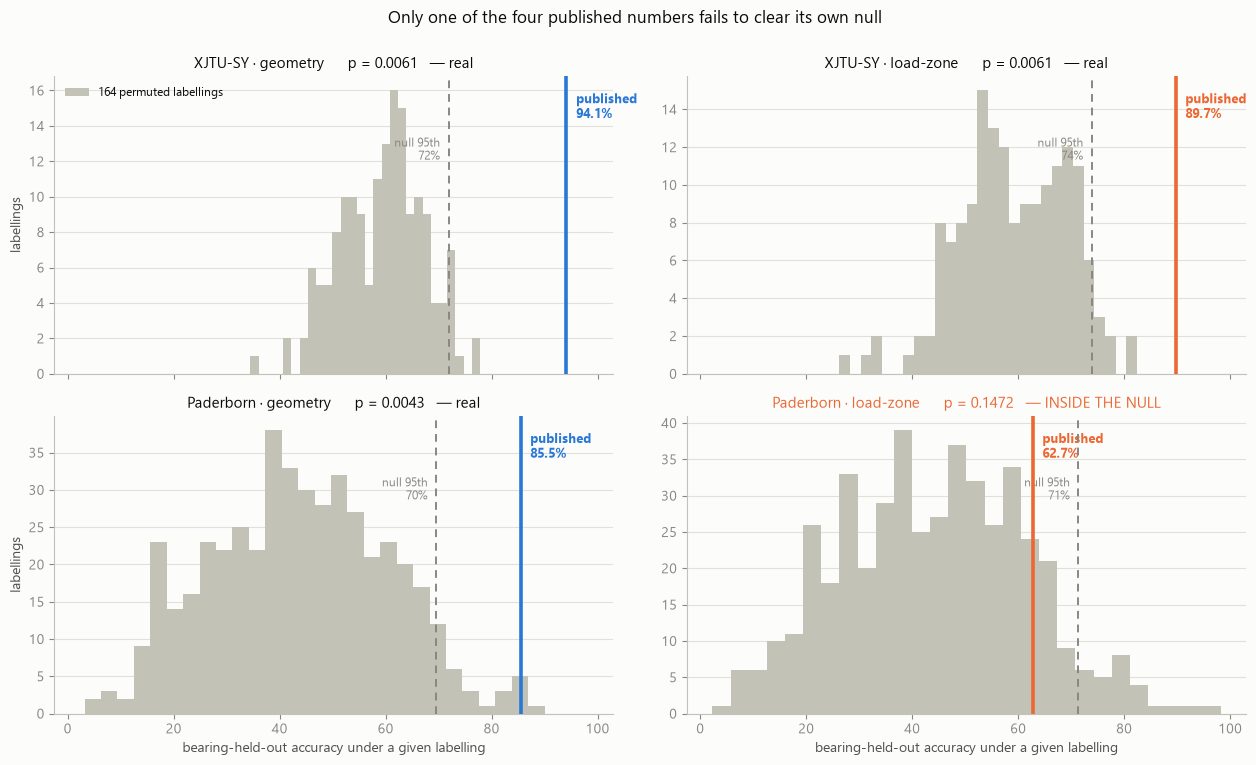

  Paderborn  geometry   85.5%  null 95th 69.5%    2/462 beat it  p=0.0043  -> real
  Paderborn  load-zone  62.7%  null 95th 71.4%   68/462 beat it  p=0.1472  -> NOT distinguishable from chance
  XJTU-SY    geometry   94.1%  null 95th 71.9%    1/165 beat it  p=0.0061  -> real
  XJTU-SY    load-zone  89.7%  null 95th 73.9%    1/165 beat it  p=0.0061  -> real


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12.8, 7.6), sharex=True)
order = [("XJTU-SY", "geometry"), ("XJTU-SY", "load-zone"),
         ("Paderborn", "geometry"), ("Paderborn", "load-zone")]
for ax, (rig, ch) in zip(axes.ravel(), order):
    g = P[(P["rig"] == rig) & (P["channel"] == ch)]
    true = float(g[g["is_true"]]["acc"].iloc[0])
    null = g[~g["is_true"]]["acc"].to_numpy()
    p = float((g["acc"] >= true).mean())
    sig = p < 0.05
    ax.hist(100 * null, bins=28, color=BASE, zorder=3,
            label=f"{len(null)} permuted labellings")
    q95 = np.quantile(null, 0.95)
    ax.axvline(100 * q95, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
    ax.annotate(f"null 95th\n{q95:.0%}", (100 * q95, ax.get_ylim()[1] * 0.72),
                xytext=(-6, 0), textcoords="offset points", fontsize=8.5,
                color=MUTED, ha="right")
    ax.axvline(100 * true, color=CH[ch], lw=2.6, zorder=5)
    ax.annotate(f"published\n{true:.1%}", (100 * true, ax.get_ylim()[1] * 0.86),
                xytext=(7, 0), textcoords="offset points", fontsize=9.5,
                color=CH[ch], weight="bold")
    ax.set_title(f"{rig} · {ch}      p = {p:.4f}"
                 f"{'   — real' if sig else '   — INSIDE THE NULL'}",
                 fontsize=10.5, color=INK if sig else C_ORANGE)
    ax.grid(axis="x", visible=False)
    if ax in axes[1]:
        ax.set_xlabel("bearing-held-out accuracy under a given labelling")
    if ax in axes[:, 0]:
        ax.set_ylabel("labellings")
axes[0, 0].legend(fontsize=8.5, loc="upper left")
fig.suptitle("Only one of the four published numbers fails to clear its own null",
             fontsize=12, y=1.0)
plt.tight_layout()
plt.show()

for _, r in S.iterrows():
    verdict = "real" if r["p"] < 0.05 else "NOT distinguishable from chance"
    print(f"  {r['rig']:10s} {r['channel']:10s} {r['true']:5.1%}  "
          f"null 95th {r['null_95']:5.1%}  {r['beat']:3d}/{r['n']} beat it  "
          f"p={r['p']:.4f}  -> {verdict}")

**Three of the four survive; one does not.**

**The project's geometry baseline is real on both rigs.** XJTU-SY 94.1 % at
**p = 0.0061** — only the true labelling itself scores that high out of 165 — and
Paderborn 85.5 % at **p = 0.0043**, beaten by 2 of 462. Notebook 14's headline
and notebook 11's are not artefacts of bearings clustering by class.

**Notebook 20's load-zone channel is real on the rig where it was measured.**
89.7 % at **p = 0.0061** on XJTU-SY, again beaten only by the true labelling. So
the shaft-synchronous fold genuinely carries race information there. That matters
for how notebook 21 should be read: the channel is not a feature that never
worked, and the failure on Paderborn is genuine **rig-dependence** rather than a
result that was always noise.

**On Paderborn the same channel carries no demonstrable signal at all.** 62.7 %
against a null whose own 95th percentile is **71.4 %**, beaten by 68 of 462
labellings, **p = 0.147**. Notebook 21 described this as underperforming geometry
by thirteen to twenty points. That was too generous: the honest statement is that
it is **inside the null**, and nothing about it is evidence of fault information
on this rig.

Two limits of the test belong with the result. Both XJTU-SY p-values are exactly
**1/165**, the floor — the test is saturated and cannot rank the two channels
against each other, only clear both. And permuting labels while holding features
fixed asks whether the class structure is real; it cannot detect a channel that
works but is weak. With eleven units the test has little power, which is itself
the next finding.

## The size of the null, and what it prices

The distributions above are wide. That is not a quirk of one rig: with eleven
units and leave-one-out, a labelling drawn at random reaches a **95th percentile
of 69–74 %** on both datasets. Any bearing-held-out attribution number below
roughly that is inside what chance achieves.

That is a ruler, and it can be laid against every attribution figure this project
has reported.

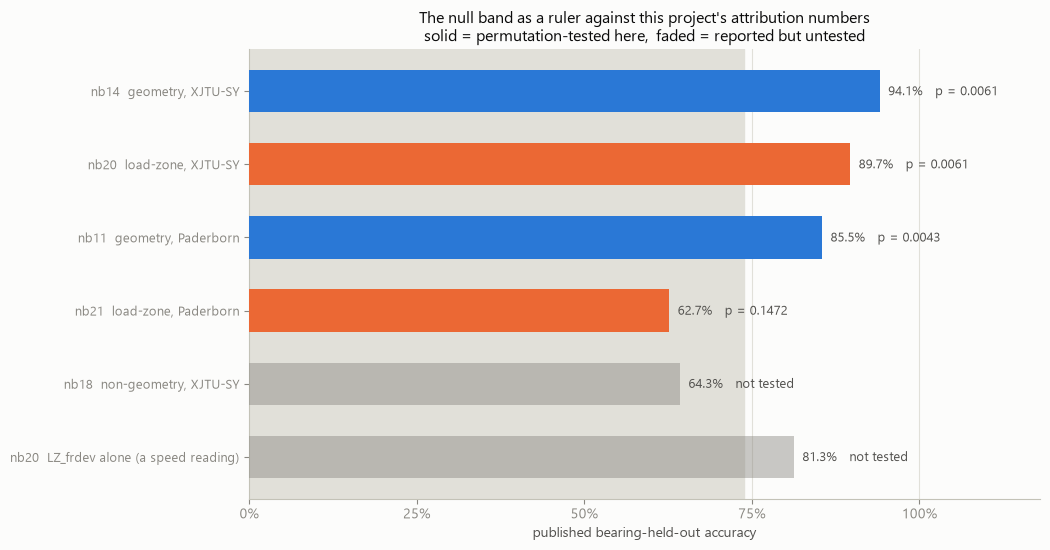

null 95th percentile across all four: 69.5% (Paderborn geometry) to 73.9% (XJTU-SY load-zone)

numbers this project has reported that sit inside that band:
  nb21  load-zone, Paderborn               62.7%
  nb18  non-geometry, XJTU-SY              64.3%


In [3]:
CLAIMS = [
    ("nb14  geometry, XJTU-SY", 0.941, "XJTU-SY", "geometry", True),
    ("nb20  load-zone, XJTU-SY", 0.897, "XJTU-SY", "load-zone", True),
    ("nb11  geometry, Paderborn", 0.855, "Paderborn", "geometry", True),
    ("nb21  load-zone, Paderborn", 0.627, "Paderborn", "load-zone", True),
    ("nb18  non-geometry, XJTU-SY", 0.643, "XJTU-SY", None, False),
    ("nb20  LZ_frdev alone (a speed reading)", 0.813, "XJTU-SY", None, False),
]
lo, hi = float(S["null_95"].min()), float(S["null_95"].max())
lo_who = S.loc[S["null_95"].idxmin(), ["rig", "channel"]].tolist()
hi_who = S.loc[S["null_95"].idxmax(), ["rig", "channel"]].tolist()

fig, ax = plt.subplots(figsize=(10.6, 5.6))
ax.axvspan(0, 100 * hi, color=GRID, zorder=1)
ax.annotate(f"inside the null band\n(95th percentile {lo:.0%}–{hi:.0%})",
            (100 * hi, len(CLAIMS) - 0.4), xytext=(-8, 0), textcoords="offset points",
            fontsize=9, color=INK2, ha="right", va="center")
y = np.arange(len(CLAIMS))
for i, (name, val, rig, ch, tested) in enumerate(CLAIMS):
    col = CH[ch] if ch else MUTED
    ax.barh(i, 100 * val, height=0.58, zorder=3, color=col,
            alpha=1.0 if tested else 0.45)
    lab = f"{val:.1%}"
    if tested:
        p = float(S[(S.rig == rig) & (S.channel == ch)]["p"].iloc[0])
        lab += f"   p = {p:.4f}"
    else:
        lab += "   not tested"
    ax.annotate(lab, (100 * val, i), xytext=(6, -3), textcoords="offset points",
                fontsize=9, color=INK2)
ax.set_yticks(y, [c[0] for c in CLAIMS], fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("published bearing-held-out accuracy")
ax.set_title("The null band as a ruler against this project's attribution numbers\n"
             "solid = permutation-tested here,  faded = reported but untested",
             fontsize=11.5)
plt.tight_layout()
plt.show()

print(f"null 95th percentile across all four: {lo:.1%} ({' '.join(lo_who)}) "
      f"to {hi:.1%} ({' '.join(hi_who)})")
print("\nnumbers this project has reported that sit inside that band:")
for name, val, rig, ch, tested in CLAIMS:
    if val <= hi:
        print(f"  {name:40s} {val:.1%}")

**Two of this project's reported numbers sit inside the band**, and it is worth
being precise about what that means for each.

Notebook 18's non-geometry channel reached **64.3 %** on XJTU-SY. That was
reported as a *negative* result — evidence that resonance and spectral-shape
features cannot attribute race — so falling inside the null is consistent with
the conclusion drawn and strengthens rather than threatens it.

Notebook 20's `LZ_frdev` reached **81.3 %**, which is *above* the band, and it is
a pure speed reading. That is the useful warning: clearing the null band is
necessary, not sufficient. The permutation test asks whether the class structure
is real given bearing-level variation; it cannot ask whether a feature is
physically capable of carrying the information, which is what caught `LZ_frdev`.
**The two controls are complementary and this project now needs both** — a
deliberately incapable feature, and a permuted-label null.

The wider consequence is about study size rather than about any one feature. A
95th percentile of **69–74 %** on eleven units means the protocol cannot resolve
a genuine but moderate effect from noise, and both XJTU-SY p-values are pinned at
the test's floor because 165 assignments cannot express anything smaller. Notebook
14 priced attribution at about six real units and notebook 17 found only 6 of 11
units clearing the RUL floor's safety target; this is the same constraint in a
third place. **Eleven units is not a limitation of the analysis, it is the
binding limitation of the evidence.**

## What this changes

1. **The project's geometry attribution is real on both rigs.** XJTU-SY 94.1 %
   at **p = 0.0061** (1 of 165) and Paderborn 85.5 % at **p = 0.0043** (2 of
   462). Notebooks 11 and 14 are not artefacts of bearings clustering by class,
   which is the reassuring half of this notebook and the half that matters most.
2. **Notebook 20's load-zone channel is real on XJTU-SY** — 89.7 % at
   **p = 0.0061**, beaten only by the true labelling. The shaft-synchronous fold
   genuinely carries race information on that rig.
3. **On Paderborn it is not.** 62.7 % against a null 95th percentile of
   **71.4 %**, p = **0.147**, beaten by 68 of 462 labellings. Notebook 21's
   "underperforms geometry by thirteen to twenty points" is corrected to
   **"inside the null"** — it is not weak evidence, it is no evidence. The
   failure is therefore genuine rig-dependence, since the same channel clears its
   null on the other rig.
4. **The null band is 69–74 % on eleven units.** Any bearing-held-out attribution
   number below roughly that is uninterpretable without this test. This prices
   every such figure the project has produced and should be reported alongside
   them.
5. **Clearing the null is necessary but not sufficient.** `LZ_frdev` — a speed
   reading incapable of diagnosing a race — scored **81.3 %**, above the band.
   The permutation test and the deliberately-incapable-feature control answer
   different questions, and this project now requires both.
6. **The test is saturated, which is itself the finding.** Both XJTU-SY p-values
   are exactly 1/165 because 165 assignments cannot express anything smaller. The
   binding constraint on every attribution claim here is the number of units, not
   the choice of features or model — the same conclusion notebooks 14 and 17
   reached from different directions.